# Building and evaluating an SQL agent
*Agentic AI Systems · SQL agent notebook*

In this notebook we:
1. **Query a database with SQL ourselves** — the task we want to automate.
2. **Build an agent that reads the database with SQL** — a language model plus a *harness*: tools and a loop.
3. **Evaluate the agent** — build a benchmark, then compare our agent with a simpler one in an A/B test.

No agent framework: every step is plain Python that you can read in `sql_agent/`.

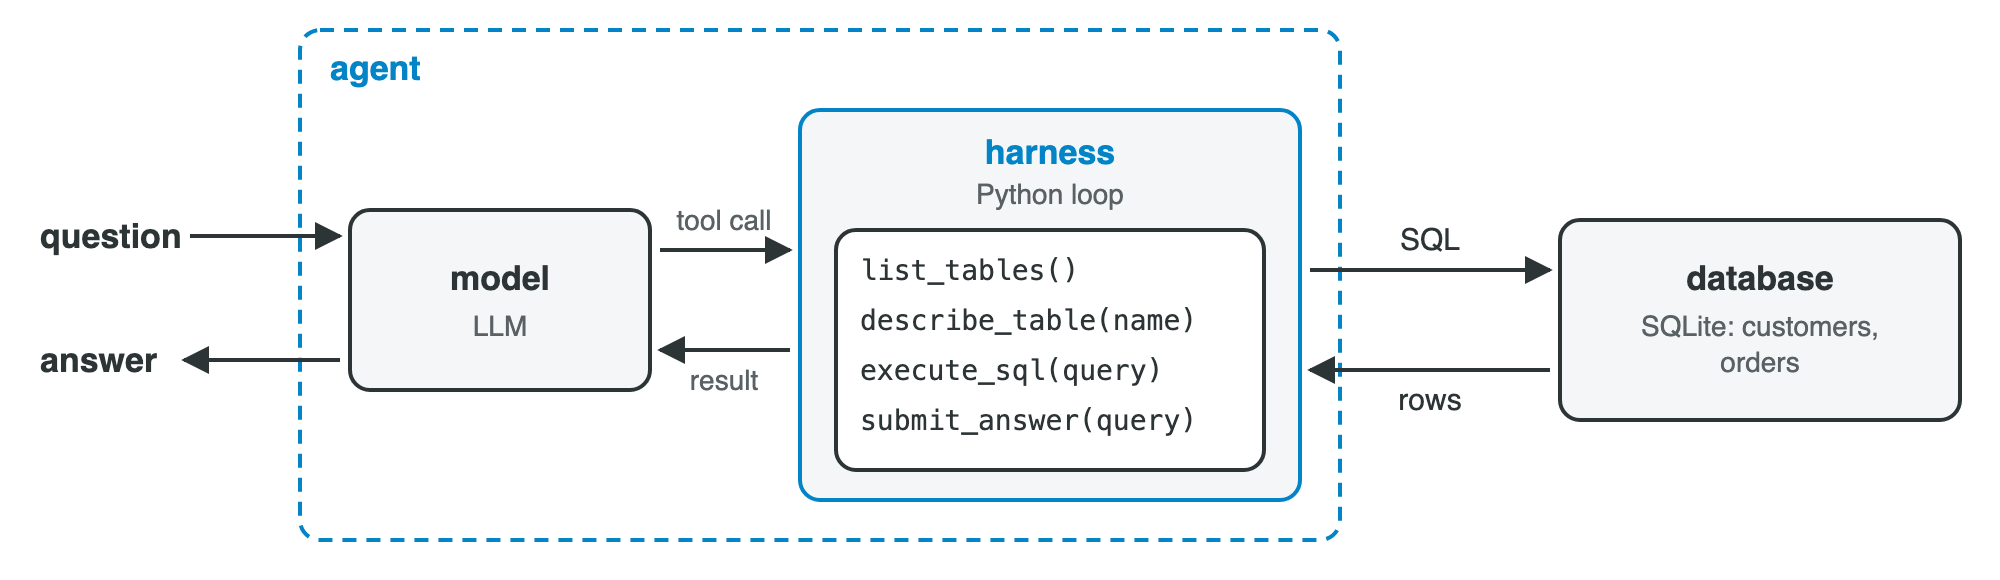

**Setup.** In a terminal, in this folder (Python 3.9 or newer):
```sh
python3 -m venv .venv && source .venv/bin/activate     # Windows: .venv\Scripts\activate
pip install -r requirements.txt
jupyter lab sql-agent.ipynb
```
Then run the cells from the top. With `LIVE = False` (the default) the notebook replays recorded model
results from `recorded/`: no API key or credits needed. To run it live with your own credits, create an
[OpenRouter](https://openrouter.ai) API key, set it in the terminal before starting Jupyter
(`export OPENROUTER_API_KEY=sk-or-...`; never paste it into the notebook), and set `LIVE = True`.
The whole notebook then costs about one cent.

In [1]:
import json, sqlite3, time
import pandas as pd
from IPython.display import display

from sql_agent import (DEFAULT_MODEL, SQLAgent, create_database, random_database, make_client,
                       run_single_shot, print_trace, print_metrics)
from sql_agent import tools, bench
from sql_agent.replay import cached

MODEL = DEFAULT_MODEL   # any OpenRouter model that supports tool calling
LIVE = False            # False: replay the last recorded run from recorded/ (no API calls)
REBUILD_BENCHMARK = False   # True: generate new benchmark questions (then audit them again)

client = make_client() if LIVE else None
DB = create_database("shop.db")          # the database file
pd.set_option("display.max_colwidth", 120)
print("model:", MODEL, "| live:", LIVE)

model: openai/gpt-oss-20b | live: False


---
## Part 1 — Querying the database with SQL
Our environment is a small shop database (SQLite) with two tables, `customers` and `orders`.
Before any model is involved, we query it ourselves.

### 1.1 The tables

In [2]:
con = sqlite3.connect(DB)     # open a connection to the database file; queries go through it

print("customers:", pd.read_sql("SELECT COUNT(*) AS n FROM customers", con).n[0], "rows")
display(pd.read_sql("SELECT * FROM customers LIMIT 3", con))
print("orders:", pd.read_sql("SELECT COUNT(*) AS n FROM orders", con).n[0], "rows")
display(pd.read_sql("SELECT * FROM orders LIMIT 3", con))

customers: 8 rows


,customer_id,name
0,1,Alice Cohen
1,2,Ben Levi
2,3,Carmen Diaz


orders: 24 rows


,order_id,customer_id,amount,order_date,status
0,101,1,120.0,2025-01-14,S
1,102,2,75.5,2025-02-03,S
2,103,3,210.0,2025-02-20,S


Each order has a `status`, stored as a one-letter code: `S` = shipped, `R` = returned, `C` = cancelled.
The meaning of the codes is **not** in the table definition — you learn it only by looking at the data.

### 1.2 Discovering the schema with SQL
SQL can also describe the database itself: which tables exist, which columns they have,
and which values appear in a column.

In [3]:
display(pd.read_sql("SELECT name FROM sqlite_master WHERE type = 'table'", con))   # tables
display(pd.read_sql("SELECT name, type FROM pragma_table_info('orders')", con))   # columns
display(pd.read_sql("SELECT DISTINCT status FROM orders", con))                   # values

,name
0,customers
1,orders


,name,type
0,order_id,INTEGER
1,customer_id,INTEGER
2,amount,REAL
3,order_date,TEXT
4,status,TEXT


,status
0,S
1,R
2,C


### 1.3 Answering questions with SQL
To answer a question, we translate it into a query. First, the three customers who spent the most:

In [4]:
query = """
SELECT c.name, COUNT(*) AS n_orders, ROUND(SUM(o.amount), 2) AS total
FROM customers c JOIN orders o ON o.customer_id = c.customer_id
GROUP BY c.customer_id
ORDER BY total DESC
LIMIT 3
"""
display(pd.read_sql(query, con))

,name,n_orders,total
0,Alice Cohen,6,610.0
1,Ben Levi,5,568.4
2,Eva Novak,2,470.0


Our running question for the rest of the notebook. From 1.2 we know the status codes,
so we can write the query by hand (`R` = returned):

In [5]:
QUESTION = "What was the total value of returned orders?"
REF = dict(bench.REFERENCE_SQL)["status: sum"]    # the reference query for this question

print(REF)
display(pd.read_sql(REF, con))
con.close()

SELECT ROUND(SUM(amount), 2) FROM orders WHERE status = 'R' /* R = returned */


,"ROUND(SUM(amount), 2)"
0,208.0


Writing these queries required knowing the tables, the columns and what the codes mean.
**An agent has to find all of this out by itself** — that is what Part 2 builds.

---
## Part 2 — An agent that reads the database with SQL
A language model only produces text. An **agent** is the model plus a **harness**: the harness gives
the model **tools** (functions it may ask to call), runs the calls the model requests, and repeats in a **loop**.

### 2.1 Tools: the same SQL reads, behind a function call
Each tool wraps one of the SQL reads from Part 1. `agent.call_tool` runs a tool exactly as the harness
does when the model asks for it.

In [6]:
agent = SQLAgent(client, MODEL, DB)

print(agent.call_tool("list_tables"))                          # SELECT name FROM sqlite_master
print(agent.call_tool("describe_table", table_name="orders"))  # pragma_table_info('orders')
print(agent.call_tool("execute_sql", query="SELECT DISTINCT status FROM orders"))

customers, orders
order_id INTEGER, customer_id INTEGER, amount REAL, order_date TEXT, status TEXT
status
S
R
C


The harness runs every tool on a **read-only** connection with a time limit and a row limit.
A failed call comes back as text the model can read, not as a crash:

In [7]:
print(agent.call_tool("execute_sql", query="DELETE FROM orders"))         # not allowed: read-only
print(agent.call_tool("execute_sql", query="SELEC name FROM customers"))  # a typo the model can fix

ERROR: OperationalError: attempt to write a readonly database
ERROR: OperationalError: near "SELEC": syntax error


The model never sees the Python code of a tool — only its name, a one-sentence description and the
arguments it takes. This is everything the model knows about its tools:

In [8]:
for t in agent.tools:
    print(f"{t['function']['name']:15s} {t['function']['description']}")

list_tables     List the tables in the database.
describe_table  List the columns and types of one table.
execute_sql     Run a read-only SQLite query and return the rows (at most 50).
submit_answer   Submit the final query. Its result is your answer, so it must return exactly what the question asks for: only the requested columns (e.g. names, not IDs) and only the requested rows.


The fourth tool, `submit_answer`, is how the model ends its work: it submits its final query,
and that query's result is the agent's answer.

### 2.2 The execution loop
1. send the conversation and the tool descriptions to the model
2. receive its reply: a request to call a tool
3. run the tool
4. append the result to the conversation
5. repeat until the model calls `submit_answer` (or a step limit is reached)

`agent.run(question)` runs this loop — about 40 lines of Python in `run_agent`, `sql_agent/agent.py`.

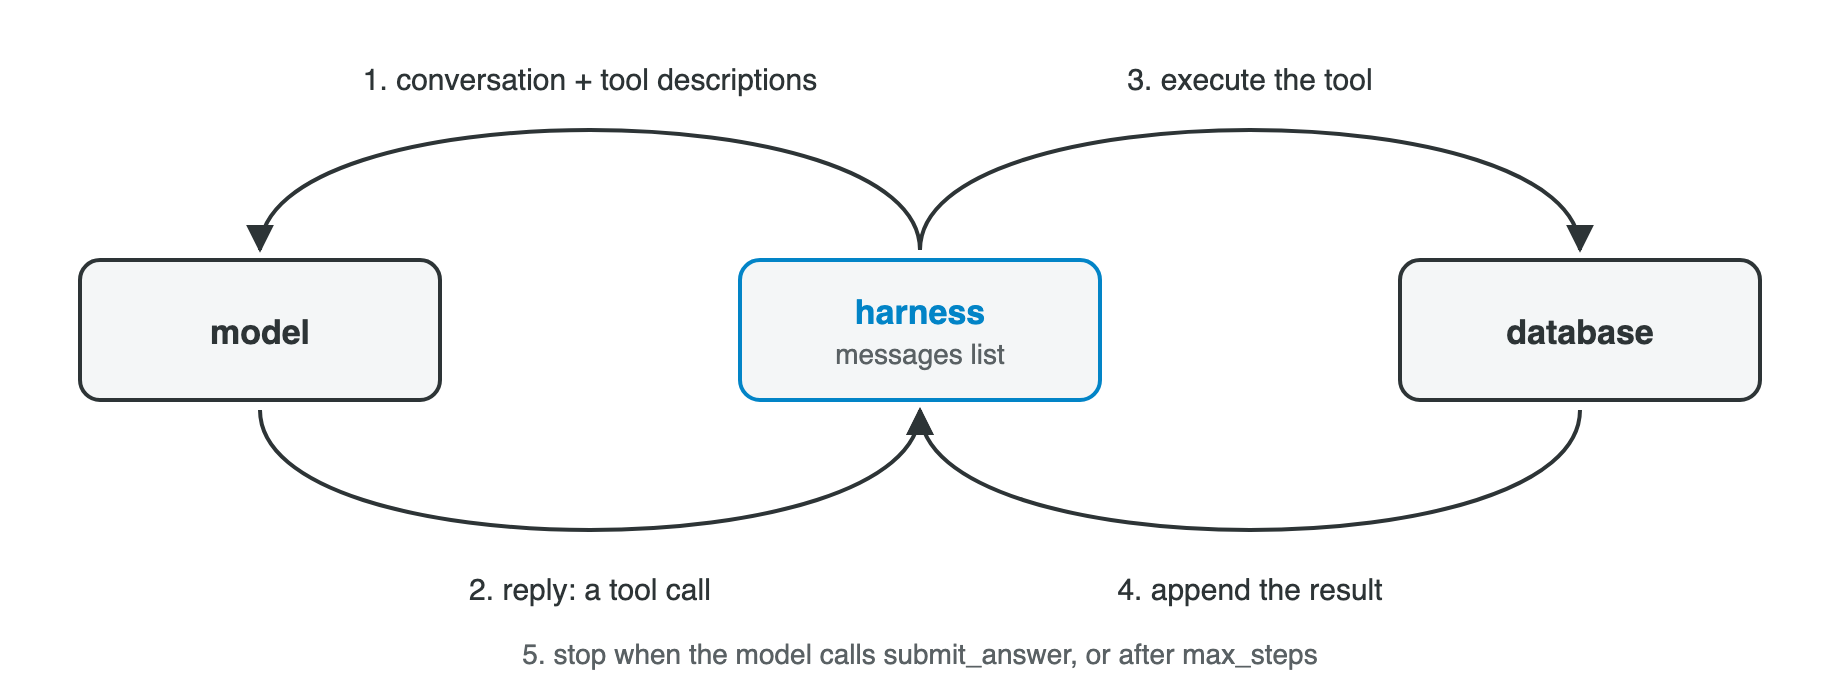

### 2.3 Run the agent

In [9]:
run = cached("run_main", lambda: agent.run(QUESTION), LIVE)
print_trace(run)

USER:
    What was the total value of returned orders?
MODEL:
    list_tables()
TOOL:
    customers, orders
MODEL:
    describe_table('customers')
TOOL:
    customer_id INTEGER, name TEXT
MODEL:
    describe_table('orders')
TOOL:
    order_id INTEGER, customer_id INTEGER, amount REAL, order_date TEXT, status TEXT
MODEL:
    execute_sql(
        SELECT SUM(amount) AS total_returned FROM orders WHERE status='returned';)
TOOL:
    total_returned
    None
MODEL:
    execute_sql(
        SELECT DISTINCT status FROM orders;)
TOOL:
    status
    S
    R
    C
MODEL:
    execute_sql(
        SELECT SUM(amount) AS total_returned FROM orders WHERE status='R';)
TOOL:
    total_returned
    208.0
MODEL:
    submit_answer(
        SELECT SUM(amount) AS total_returned FROM orders WHERE status='R';)
TOOL:
    total_returned
    208.0
[status: ok]


**Reading the trace:** `USER` is the question; each `MODEL` line is a tool call the model requested;
each `TOOL` line is what the harness sent back; a `HARNESS` line is a reminder from the harness.
The model saw only the question. Watch how it finds out what the status codes mean: it has to look at
the data, sometimes after a first guess that returns nothing.

What the run cost:

In [10]:
print_metrics(run)

model calls      7
tool calls       7
LLM latency        4.702 s
tool latency        7.52 ms
harness overhead    1.06 ms
end-to-end         4.710 s
tokens in / out  3341 / 313
cost             $0.000316


*model calls* = rounds of the loop; *tool calls* = tools executed; *LLM latency* = time waiting for the
model; *tool latency* = time running SQL; *harness overhead* = everything else; *tokens* = text sent to and
from the model; *cost* = what OpenRouter charged.

### 2.4 Was the answer right?
We compare the **result** of the agent's submitted query with the result of our reference query from Part 1.

In [11]:
print("agent's query:\n ", run.final_sql)
print("agent's result:    ", bench.result_of(DB, run.final_sql) if run.final_sql else None)
print("reference result:  ", bench.result_of(DB, REF))
print("correct (S = 1)?   ", bench.score(DB, run.final_sql, REF))

agent's query:
  SELECT SUM(amount) AS total_returned FROM orders WHERE status='R';
agent's result:     [(208.0,)]
reference result:   [(208.0,)]
correct (S = 1)?    1


### 2.5 Speed: raw SQL vs. the agent
Running a query we already know takes well under a millisecond. The agent first has to work out
*which* query to run — and that is where all its time goes.

In [12]:
# raw SQL: run the reference query directly, 100 times, take the median
times = []
for _ in range(100):
    t0 = time.perf_counter()
    tools.run_query(DB, REF)
    times.append(time.perf_counter() - t0)
t_sql = bench.percentile(times, 50)

m = run.metrics      # the agent's run on the same question (section 2.3)
print(f"raw SQL query       {t_sql * 1000:9.2f} ms")
print(f"agent, end to end   {m.t_total * 1000:9.0f} ms   = {m.t_total / t_sql:,.0f}x slower")
print(f"  running SQL       {m.t_tools * 1000:9.2f} ms   ({m.tool_calls} tool calls)")
print(f"  waiting for model {m.t_llm * 1000:9.0f} ms   ({m.model_calls} model calls)")

raw SQL query            0.07 ms
agent, end to end        4710 ms   = 72,375x slower
  running SQL            7.52 ms   (7 tool calls)
  waiting for model      4702 ms   (7 model calls)


The agent is **orders of magnitude slower** than raw SQL (the factor above), and almost all of that time is
spent waiting for the model — the SQL it runs takes only milliseconds. An agent pays off when we do **not** know the query;
when we do, plain code is the right tool.

---
## Part 3 — Evaluating the agent: a benchmark and an A/B test
One correct answer is a demonstration, not a measurement: with one question we learn nothing about how
often the agent is right. To evaluate an agent — and to compare two agents — we need
**many tasks with known answers**, a **score**, and a **fair comparison**.

### 3.1 Building a benchmark from SQL
We start from reference queries, whose answers are correct by construction:
1. write a reference query $\mathrm{SQL}^*_i$,
2. let an LLM turn it into a natural-language question $q_i$,
3. run the query to get the reference answer $r^*_i$.

Task $i$ is the pair $(q_i, r^*_i)$. The agent sees only the question, never the reference query.

Our 20 reference queries: 8 basic SQL structures, 4 harder SQL (ties, date arithmetic, window functions),
and 8 that depend on the status codes.

In [13]:
pd.DataFrame(bench.REFERENCE_SQL, columns=["kind", "reference SQL"])

,kind,reference SQL
0,filter,SELECT COUNT(*) FROM orders WHERE order_date >= '2026-01-01'
1,aggregation,"SELECT ROUND(AVG(amount), 2) FROM orders WHERE order_date BETWEEN '2025-01-01' AND '2025-12-31'"
2,join + group,"SELECT c.name, ROUND(SUM(o.amount), 2) FROM customers c JOIN orders o ON o.customer_id = c.customer_id WHERE o.order..."
3,join + order,SELECT c.name FROM customers c JOIN orders o ON o.customer_id = c.customer_id GROUP BY c.customer_id ORDER BY SUM(o....
4,nested,SELECT order_id FROM orders WHERE amount > (SELECT AVG(amount) FROM orders)
5,negation,SELECT name FROM customers WHERE customer_id NOT IN (SELECT customer_id FROM orders)
6,negation + join,SELECT DISTINCT c.name FROM customers c JOIN orders o ON o.customer_id = c.customer_id WHERE o.order_date LIKE '2025...
7,group + having,SELECT c.name FROM customers c JOIN orders o ON o.customer_id = c.customer_id GROUP BY c.customer_id HAVING COUNT(*)...
8,ties,SELECT c.name FROM customers c JOIN orders o ON o.customer_id = c.customer_id WHERE o.order_date LIKE '2026%' GROUP ...
9,date difference,SELECT CAST(julianday(MAX(o.order_date)) - julianday(MIN(o.order_date)) AS INTEGER) FROM orders o JOIN customers c O...


The LLM writes one question per query (the prompt is `bench.QUESTION_PROMPT`). It must not reveal
column names or stored codes — "status C" would hand the answer to the agent. A check (`bench.leaks_schema`)
catches such questions and asks the LLM to rewrite them.

In [14]:
# frozen after the audit: regenerated only if REBUILD_BENCHMARK is True
benchmark = cached("benchmark", lambda: bench.build_benchmark(client, MODEL, DB),
                   LIVE and REBUILD_BENCHMARK)
print(f"benchmark size: n = {len(benchmark)} tasks")
pd.DataFrame(benchmark)[["kind", "question", "result"]]

benchmark size: n = 20 tasks


,kind,question,result
0,filter,"How many orders were placed on or after January 1, 2026?",[[11]]
1,aggregation,"What is the average amount of orders placed between January 1, 2025 and December 31, 2025, rounded to two decimal pl...",[[135.03]]
2,join + group,"Which customers placed orders in 2025, and what is the total amount of those orders, rounded to two decimal places?","[[Alice Cohen, 220.0], [Ben Levi, 175.4], [Carmen Diaz, 290.0], [David Mizrahi, 355.0], [Eva Novak, 470.0], [Farid H..."
3,join + order,Which customer has the highest total order amount across all orders?,[[Alice Cohen]]
4,nested,Which order IDs have an amount above the average amount of all orders?,"[[103], [105], [108], [111], [114], [116], [120], [123]]"
5,negation,Which customers have never placed an order?,[[Hiro Tanaka]]
6,negation + join,Which customers placed orders in 2025 but did not place any orders in 2026?,"[[David Mizrahi], [Eva Novak], [Farid Haddad]]"
7,group + having,Which customers have placed four or more orders?,"[[Alice Cohen], [Ben Levi], [Carmen Diaz]]"
8,ties,Which customer(s) placed the most orders in 2026?,"[[Alice Cohen], [Ben Levi], [Grace Kim]]"
9,date difference,How many days are between Alice Cohen’s earliest and latest orders?,[[596]]


**Audit before use.** Read each question against its query: does it describe the query exactly
(dates, rounding, what is returned)? An LLM-generated question can be subtly wrong.
After the audit the benchmark is **frozen**: later runs reuse the same questions (`REBUILD_BENCHMARK = False`).

**Benchmark size.** $n = 20$ tasks on one small database: enough to show the method, not to measure
performance precisely — each task is 5% of the success rate. Public text-to-SQL benchmarks are far larger:
Spider has about 10,000 questions over 200 databases, BIRD about 12,750 over 95 databases.

### 3.2 Scoring: compare results, not SQL
Task $i$ is solved if the agent's result equals the reference result: $S_i = \mathbf 1\{\hat r_i = r^*_i\}$.
We compare results because two different queries can be equally correct.

This opens a loophole: a query can get $S_i = 1$ without computing anything — for example, `SELECT 208.0`,
the number itself. A model that has seen the benchmark (for example, in its training data) can **memorize** answers
like this and score well without solving the task: a form of **reward hacking** — maximizing the score
rather than doing the task.

Defense: score on several databases with the same tables but random data. A query that computes the
answer stays correct; a memorized answer does not.

In [15]:
# three more databases: same tables and customers, random orders and statuses
DBS = [DB] + [random_database(f"shop_random_{s}.db", seed=s) for s in range(3)]

# the correct answer to our question changes with the data
for db in DBS:
    print(f"{str(db):18s} {bench.result_of(db, REF)}")

shop.db            [(208.0,)]
shop_random_0.db   [(530.74,)]
shop_random_1.db   [(417.79,)]
shop_random_2.db   [(1190.4,)]


In [16]:
# a query that memorized the answer on our database instead of computing it
memorized = "SELECT 208.0"

queries = {"agent's query": run.final_sql, "memorized answer": memorized}
pd.DataFrame({
    "S on our database": {k: bench.score(DB, q, REF) for k, q in queries.items()},
    "S on all 4 databases": {k: bench.score_multi(DBS, q, REF) for k, q in queries.items()},
})

,S on our database,S on all 4 databases
agent's query,1,1
memorized answer,1,0


### 3.3 Two agents to compare
Is our agent better than a simpler design? We compare two harnesses **around the same model**:

| | Agent | How it answers |
|---|---|---|
| $H_A$ | one-shot | the table definitions are pasted into the prompt; the model writes one query; the harness runs it. No tools, no feedback, no second try. |
| $H_B$ | our agent (Part 2) | the model explores with tools, sees results and errors, and ends with `submit_answer`. |

Each agent is a function from a question to a run. Only the harness differs; the model is the same.

In [17]:
from sql_agent.agent import SINGLE_SHOT_PROMPT

def H_A(question):                       # one-shot: a single model call
    return run_single_shot(client, MODEL, DB, question)

H_B = SQLAgent(client, MODEL, DB).run    # our agent: the loop of Part 2

# To compare models instead, keep the harness and change the model, e.g.
#   H_B_nemo = SQLAgent(client, "mistralai/mistral-nemo", DB).run

print("H_A sends this single prompt to the model:\n")
print(SINGLE_SHOT_PROMPT.format(schema=tools.schema_text(DB), question=QUESTION))

H_A sends this single prompt to the model:

SQLite schema:
customers(customer_id INTEGER, name TEXT)
orders(order_id INTEGER, customer_id INTEGER, amount REAL, order_date TEXT, status TEXT)

Write one SQLite query that answers the question. The query must return
exactly the answer (no extra columns or rows).
Reply with the query only, inside ```sql ... ```.

Question: What was the total value of returned orders?


Note what $H_A$ sees: the tables and columns, but **not the data** — so it cannot know the status codes.

### 3.4 Metrics
| Metric | Definition |
|---|---|
| success $Y_i \in \{0,1\}$ | 1 if the agent's result on task $i$ equals the reference result |
| success rate $\hat J$ | fraction of tasks solved: $\frac1n \sum_i Y_i$ |
| paired difference $\hat\Delta$ | $\hat J_B - \hat J_A = \frac1n \sum_i (Y^B_i - Y^A_i)$ |
| 95% confidence interval | $\hat\Delta \pm 1.96\,\widehat{\mathrm{SE}}$, where $\widehat{\mathrm{SE}}$ = standard deviation of the $Y^B_i - Y^A_i$ divided by $\sqrt n$ (normal approximation) |
| latency | seconds per task, end to end (P50 = median) |
| cost | dollars per task; cost per success = total cost / number of tasks solved |

**Why paired:** both agents get the same tasks, so easy and hard tasks affect both equally.
Only tasks where exactly one agent succeeds change $\hat\Delta$.

### 3.5 Run the A/B test
Both agents answer all 20 questions (several minutes when live).

In [18]:
def ab_test():
    rows = []
    for ex in benchmark:
        a, b = H_A(ex["question"]), H_B(ex["question"])
        rows.append({"kind": ex["kind"],
                     "y_A": bench.score(DB, a.final_sql, ex["sql"]),
                     "y_B": bench.score(DB, b.final_sql, ex["sql"]),
                     "t_A": a.metrics.t_total, "t_B": b.metrics.t_total,
                     "cost_A": a.metrics.cost, "cost_B": b.metrics.cost,
                     "sql_A": a.final_sql, "sql_B": b.final_sql})
    return rows

ab = pd.DataFrame(cached("ab", ab_test, LIVE))
ab[["kind", "y_A", "y_B"]]          # 1 = solved, 0 = not solved

,kind,y_A,y_B
0,filter,1,1
1,aggregation,1,1
2,join + group,1,1
3,join + order,1,1
4,nested,1,1
5,negation,1,1
6,negation + join,1,1
7,group + having,1,1
8,ties,1,1
9,date difference,1,1


### 3.6 Results

In [19]:
def summary(y, t, cost):
    return {"success rate": f"{y.mean():.0%}",
            "P50 latency (s)": round(bench.percentile(list(t), 50), 2),
            "cost per task ($)": round(cost.mean(), 6),
            "cost per success ($)": round(cost.sum() / y.sum(), 6) if y.sum() else None}

pd.DataFrame({"H_A one-shot": summary(ab.y_A, ab.t_A, ab.cost_A),
              "H_B agent": summary(ab.y_B, ab.t_B, ab.cost_B)})

,H_A one-shot,H_B agent
success rate,60%,95%
P50 latency (s),7.09,3.58
cost per task ($),0.000065,0.000252
cost per success ($),0.000108,0.000265


In [20]:
res = bench.paired_ab(list(ab.y_A), list(ab.y_B))
print(f"paired difference   J_B - J_A = {res['delta_hat']:+.0%}   (n = {res['n']} tasks)")
print(f"only H_A solved: {res['only_A']}   only H_B solved: {res['only_B']}")
print("95% confidence interval: [{:+.0%}, {:+.0%}]".format(*res["normal_ci"]))

paired difference   J_B - J_A = +35%   (n = 20 tasks)
only H_A solved: 0   only H_B solved: 7
95% confidence interval: [+14%, +56%]


**Where do they differ?** The tasks solved by exactly one agent, with each agent's query:

In [21]:
ab[ab.y_A != ab.y_B][["kind", "y_A", "sql_A", "y_B", "sql_B"]]

,kind,y_A,sql_A,y_B,sql_B
12,status: sum,0,"SELECT ROUND(SUM(amount), 2) FROM orders WHERE status = 'returned';",1,"SELECT ROUND(SUM(amount),2) AS total FROM orders WHERE status='R';"
14,status: join,0,SELECT DISTINCT c.name\nFROM customers c\nJOIN orders o ON c.customer_id = o.customer_id\nWHERE o.status = 'returned';,1,SELECT DISTINCT c.name FROM customers c JOIN orders o ON c.customer_id=o.customer_id WHERE o.status='R';
15,status: ratio,0,"SELECT ROUND(100.0 * SUM(CASE WHEN status = 'returned' THEN 1 ELSE 0 END) / COUNT(*), 1)\nFROM orders;",1,"SELECT ROUND(100.0 * SUM(CASE WHEN status='R' THEN 1 ELSE 0 END) / COUNT(*), 1) AS returned_percentage FROM orders;"
16,status: revenue,0,"SELECT round(SUM(amount), 2)\nFROM orders\nWHERE status = 'shipped'\n AND strftime('%Y', order_date) = '2025';",1,"SELECT ROUND(SUM(amount),2) AS total_shipped_2025 FROM orders WHERE status='S' AND strftime('%Y', order_date)='2025';"
17,status: top customer,0,SELECT c.name\nFROM customers c\nJOIN orders o ON c.customer_id = o.customer_id\nWHERE o.status = 'cancelled'\nGROUP...,1,"SELECT c.name FROM customers c JOIN (SELECT customer_id, SUM(amount) AS total_cancelled FROM orders WHERE status='C'..."
18,status: count + date,0,"SELECT COUNT(*) FROM orders\nWHERE status = 'shipped'\n AND strftime('%Y', order_date) = '2026';",1,"SELECT COUNT(*) FROM orders WHERE status='S' AND strftime('%Y', order_date)='2026';"
19,status: average,0,"SELECT ROUND(AVG(amount), 2) FROM orders WHERE status = 'shipped';",1,"SELECT ROUND(AVG(amount), 2) AS avg_shipped_amount FROM orders WHERE status = 'S';"


**Where do both fail?** Tasks that neither agent solved:

In [22]:
ab[(ab.y_A == 0) & (ab.y_B == 0)][["kind", "sql_A", "sql_B"]]

,kind,sql_A,sql_B
13,status: count,SELECT COUNT(*) FROM orders WHERE status <> 'cancelled';,SELECT COUNT(*) AS total_not_cancelled FROM orders WHERE status <> 'cancelled';


The loop helps only when an observation **looks** wrong. When a wrong guess returns nothing, the agent
notices and investigates. When it returns a *plausible* number — for example, `status <> 'cancelled'`
counts every order, because no row is literally `'cancelled'` — the agent has no signal that anything is
wrong, and submits it.

**How sure are we?** With 20 tasks one task moves $\hat\Delta$ by 5 points, so the interval is wide.
It is also a normal approximation, which becomes accurate only as $n$ grows: a larger benchmark would give
a narrower and more reliable interval.

---
## Appendix — latency for the evaluation slides
Running a known query vs. letting a model decide which query to run: the running question, `R` times each.
Only time is measured here, not correctness.

In [23]:
R = 10   # repetitions per approach

def measure_latency():
    out = {"direct SQL": [], "one-shot (H_A)": [], "agent (H_B)": []}
    for _ in range(R):
        t0 = time.perf_counter(); tools.run_query(DB, REF); out["direct SQL"].append(time.perf_counter() - t0)
        out["one-shot (H_A)"].append(H_A(QUESTION).metrics.t_total)
        out["agent (H_B)"].append(H_B(QUESTION).metrics.t_total)
    return out

lat = cached("latency", measure_latency, LIVE)
pd.DataFrame({k: {"P50 (s)": bench.percentile(v, 50), "P95 (s)": bench.percentile(v, 95),
                  "mean (s)": sum(v) / len(v)} for k, v in lat.items()}).T

,P50 (s),P95 (s),mean (s)
direct SQL,0.000433,0.000853,0.000456
one-shot (H_A),3.698786,13.568903,5.383644
agent (H_B),4.009543,5.894032,4.345980
